In [1]:
import pandas as pd
import json
import plotly.express as px
import numpy as np

# Prepare data

In [2]:
# Load chiller_plant_dataset.parquet
chiller_data = pd.read_parquet('data/chiller_plant_dataset.parquet')
if not isinstance(chiller_data.index, pd.DatetimeIndex):
    chiller_data.index = pd.to_datetime(chiller_data.index, utc=True).tz_convert('Asia/Bangkok')
if getattr(chiller_data.index, 'tz', None) is not None:
    chiller_data.index = chiller_data.index.tz_convert('Asia/Bangkok').tz_localize(None)

with open('data/columns_info.json') as f:
    columns_info = json.load(f)

In [3]:
# Drop columns
import ast

column_list = chiller_data.columns.to_list()
columns_info_list = []
for key in columns_info:
    tup = ast.literal_eval(key)
    columns_info_list.append(tup)
columns_to_drop = [col for col in column_list if col not in columns_info_list]
columns_to_drop.append(('chiller_6', 'power'))
chiller_data = chiller_data.drop(columns=columns_to_drop)
chiller_data.shape

(77014, 191)

In [4]:
# Remove NaN
chiller_data.ffill(inplace=True)
chiller_data.bfill(inplace=True)
chiller_data.isnull().sum().sum()

np.int64(0)

In [5]:
# Remove negative values
# Check which columns have negative values
negative_columns = chiller_data.columns[chiller_data.lt(0).any()]

# Count negative values in each column
negative_counts = chiller_data[negative_columns].lt(0).sum().sum()

print("negative values:")
print(negative_counts)

# Replace negative values with NaN
chiller_data[negative_columns] = chiller_data[negative_columns].mask(chiller_data[negative_columns] < 0)
# Forward fill NaN values
chiller_data.ffill(inplace=True)
chiller_data.bfill(inplace=True)

# Verify if negative values are replaced
negative_counts_after_fill = chiller_data[negative_columns].lt(0).sum().sum()

print("negative values after forward filling:")
print(negative_counts_after_fill)

negative values:
12838
negative values after forward filling:
0


In [6]:
# Change Multidexing to normal columns name
chiller_data.columns = ['_'.join(col) if isinstance(col, tuple) else col for col in chiller_data.columns]

# Load pre-processed data

In [7]:
chiller_data = pd.read_parquet('chiller_data_pre.parquet')
if not isinstance(chiller_data.index, pd.DatetimeIndex):
    chiller_data.index = pd.to_datetime(chiller_data.index, utc=True).tz_convert('Asia/Bangkok')
if getattr(chiller_data.index, 'tz', None) is not None:
    chiller_data.index = chiller_data.index.tz_convert('Asia/Bangkok').tz_localize(None)

In [8]:
chiller_data[['plant_individual_cdw_flow','condenser_water_loop_flow_rate']].describe()

,plant_individual_cdw_flow,condenser_water_loop_flow_rate
count,77014.000000,77014.000000
mean,1526.162565,3239.942738
std,661.432930,2615.518168
min,0.000000,0.000000
25%,1480.000000,1480.000000
50%,1550.000000,1600.000000
75%,1757.500000,5280.000000
max,8630.000000,11600.000000


# EDA

# Chiller model (Cooling rate)

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



chiller_1_cooling_rate SARIMAX MSE: 13555.290998101513
chiller_1_cooling_rate SARIMAX MAE: 56.90667645641982
chiller_1_cooling_rate SARIMAX R²: 0.7887589091955465
chiller_1_cooling_rate SARIMAX CvRMSE: 0.8535023768330595


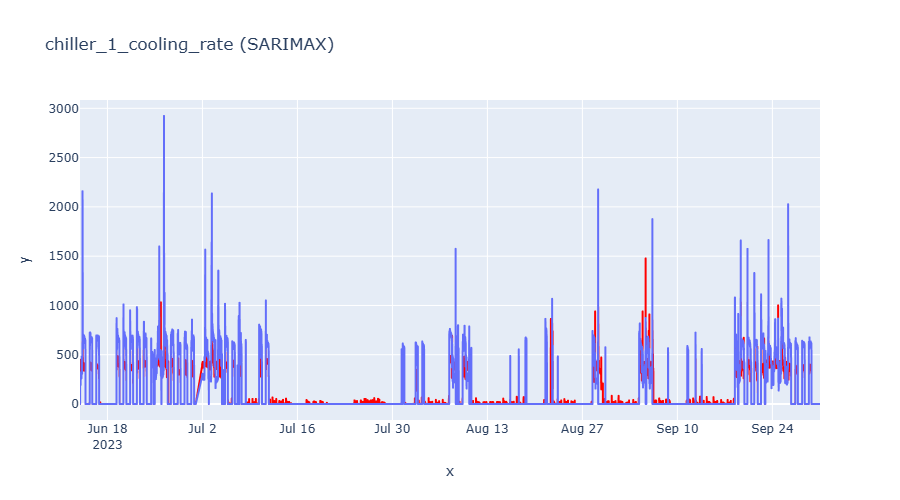

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



chiller_2_cooling_rate SARIMAX MSE: 20294.975188338452
chiller_2_cooling_rate SARIMAX MAE: 107.83356976464975
chiller_2_cooling_rate SARIMAX R²: 0.7665169076850259
chiller_2_cooling_rate SARIMAX CvRMSE: 0.5714411802973464


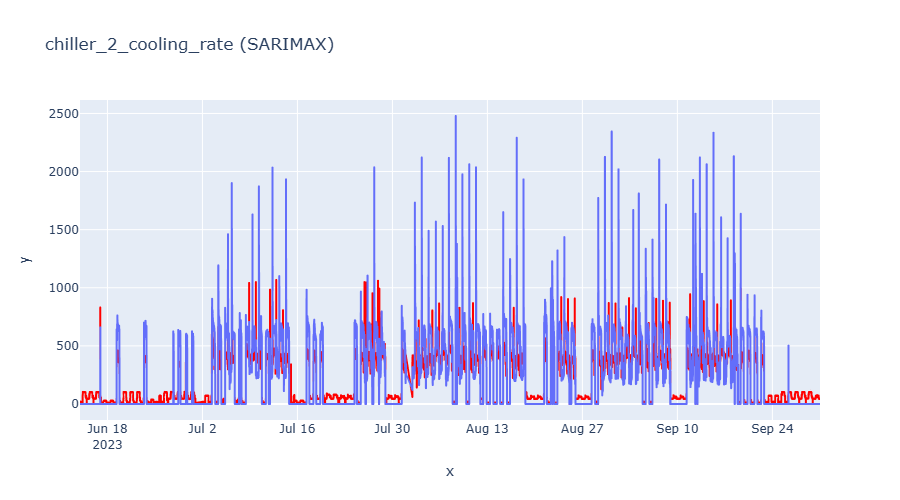

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



chiller_3_cooling_rate SARIMAX MSE: 27947.708751561022
chiller_3_cooling_rate SARIMAX MAE: 114.5672534282257
chiller_3_cooling_rate SARIMAX R²: 0.7005778008390469
chiller_3_cooling_rate SARIMAX CvRMSE: 0.5569856226103628


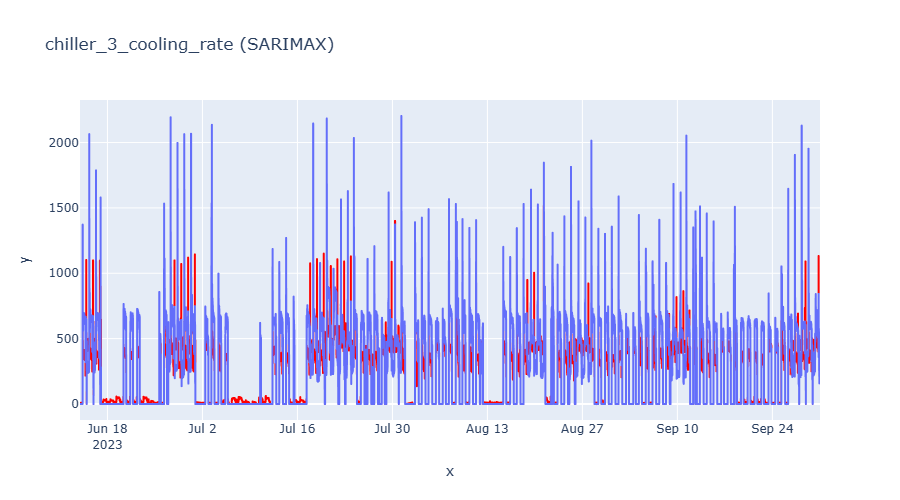

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



chiller_4_cooling_rate SARIMAX MSE: 14366.644727977578
chiller_4_cooling_rate SARIMAX MAE: 79.56546656261231
chiller_4_cooling_rate SARIMAX R²: 0.8477002609366655
chiller_4_cooling_rate SARIMAX CvRMSE: 0.44471163275755504


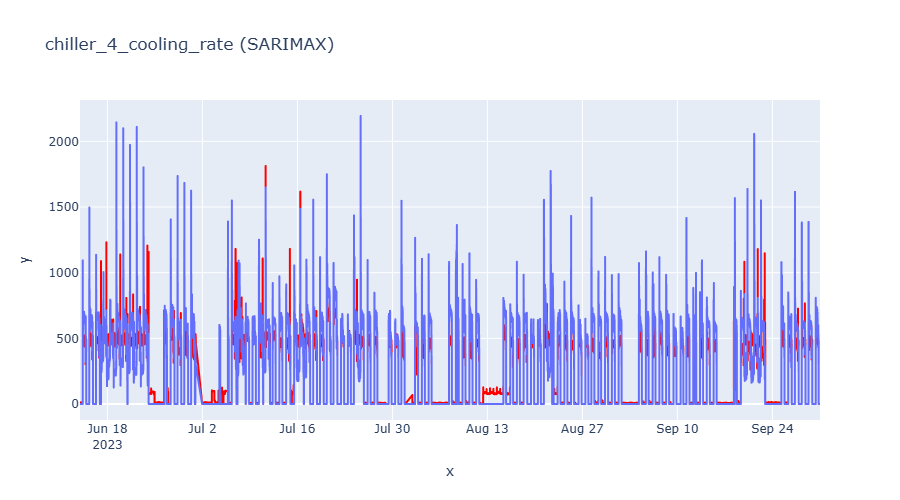

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



chiller_5_cooling_rate SARIMAX MSE: 13138.515088338801
chiller_5_cooling_rate SARIMAX MAE: 65.14739903607222
chiller_5_cooling_rate SARIMAX R²: 0.851302805666954
chiller_5_cooling_rate SARIMAX CvRMSE: 0.5562441595657832


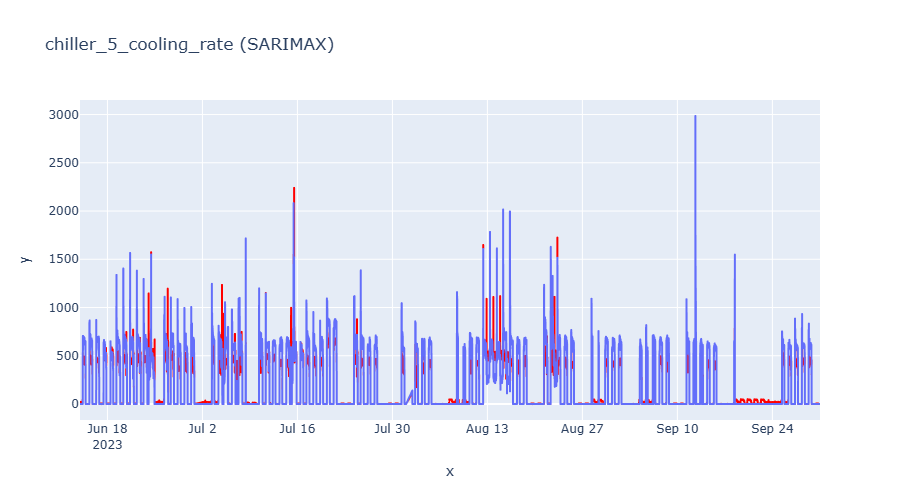

In [9]:
import pandas as pd
import numpy as np
import plotly.express as px
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


chillers_feature = [f'chiller_{i}_cond_water_flow_rate' for i in range(1, 6)] + \
                [f'chiller_{i}_evap_water_flow_rate' for i in range(1, 6)] + \
                [f'chiller_{i}_status_read' for i in range(1, 6)]

chillers_target = [f'chiller_{i}_cooling_rate' for i in range(1, 6)]

X = chiller_data[chillers_feature]
y = chiller_data[chillers_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

# SARIMAX is univariate, so fit one cooling-rate series at a time
for target in chillers_target:
    y_train_i = y_train[target]
    y_test_i = y_test[target]

    sarimax_model = SARIMAX(y_train_i, exog=X_train, order=(2, 1, 3), seasonal_order=(0, 0, 0, 0))
    sarimax_result = sarimax_model.fit()

    y_pred_sarimax = sarimax_result.forecast(steps=len(X_test), exog=X_test, index=X_test.index)
    y_pred_sarimax = np.maximum(y_pred_sarimax, 0)

    mse_sarimax = mean_squared_error(y_test_i, y_pred_sarimax)
    mae_sarimax = mean_absolute_error(y_test_i, y_pred_sarimax)
    r2_sarimax = r2_score(y_test_i, y_pred_sarimax)
    cvrmse_sarimax = cvrmse(y_test_i, y_pred_sarimax)

    print(f"{target} SARIMAX MSE: {mse_sarimax}")
    print(f"{target} SARIMAX MAE: {mae_sarimax}")
    print(f"{target} SARIMAX R²: {r2_sarimax}")
    print(f"{target} SARIMAX CvRMSE: {cvrmse_sarimax}")

    fig = px.line(x=X_test.index, y=y_pred_sarimax, title=f'{target} (SARIMAX)')
    fig.update_traces(line_color='red', name=f'{target} (SARIMAX)')
    fig.add_trace(px.line(x=X_test.index, y=y_test_i).data[0])
    fig.show()

# Cdps model (Condenser water flow)

## Ridge regression

Ridge Regression MSE: 215.56034289558144
Ridge Regression MAE: 8.192127543464625
Ridge Regression R²: 0.8434124201489817
Ridge Regression CvRMSE: 0.35317735595111494


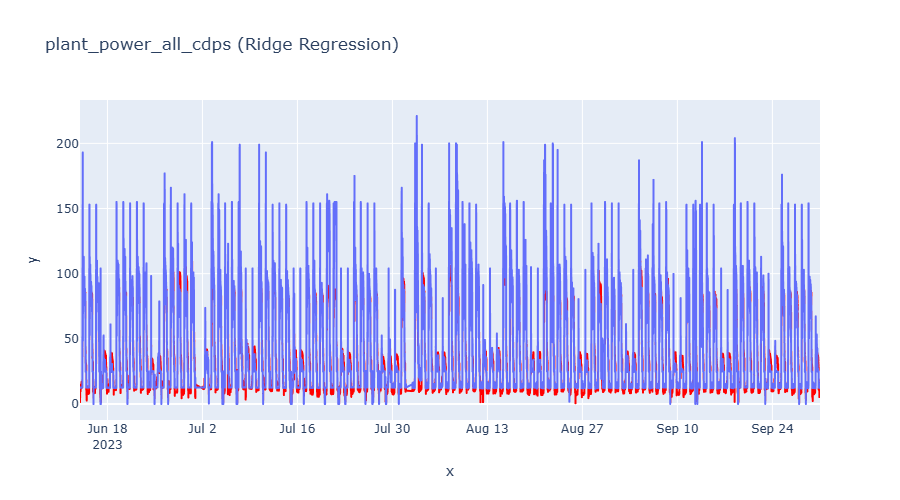

In [10]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Assuming chiller_data is already loaded

cdps_feature = ['plant_cooling_rate'] + \
                [f'chiller_{i}_cond_water_flow_rate' for i in range(1, 6)]

cdps_target = ['plant_power_all_cdps']

X = chiller_data[cdps_feature]
y = chiller_data[cdps_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the Ridge model
ridge_model = Ridge(alpha=1.0)  # You can adjust the regularization parameter alpha as needed
ridge_model.fit(X_train, y_train)

# Predict
y_pred_ridge = ridge_model.predict(X_test)
y_pred_ridge = y_pred_ridge.clip(min=0)

# Performance Metrics for Ridge Regression
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

cvrmse_ridge = cvrmse(y_test, y_pred_ridge)

# Print metrics for Ridge Regression
print(f"Ridge Regression MSE: {mse_ridge}")
print(f"Ridge Regression MAE: {mae_ridge}")
print(f"Ridge Regression R²: {r2_ridge}")
print(f"Ridge Regression CvRMSE: {cvrmse_ridge}")

# Plotting
y_pred_ridge_df = pd.DataFrame(y_pred_ridge, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_ridge_df[cdps_target[0]], title=f'{cdps_target[0]} (Ridge Regression)')
fig.update_traces(line_color='red', name=f'{cdps_target[0]} (Ridge)')
fig.add_trace(px.line(x=X_test.index, y=y_test[cdps_target[0]]).data[0])
fig.show()

## SARIMAX

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.



SARIMAX MSE: 1214.7761968697212
SARIMAX MAE: 30.597603309727564
SARIMAX R²: 0.11756094755983537
SARIMAX CvRMSE: 0.838410202922609


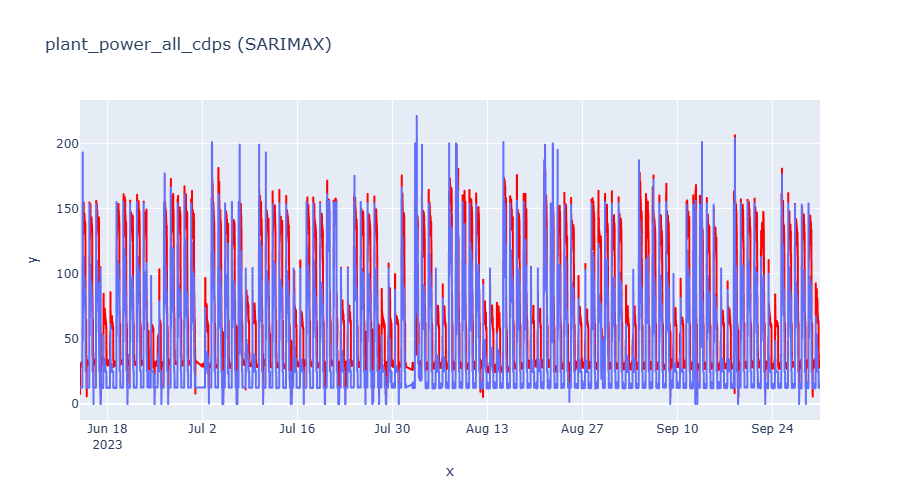

In [11]:
import pandas as pd
import numpy as np
import plotly.express as px
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


cdps_feature = ['plant_cooling_rate'] + \
                [f'chiller_{i}_cond_water_flow_rate' for i in range(1, 6)]

cdps_target = ['plant_power_all_cdps']

X = chiller_data[cdps_feature]
y = chiller_data[cdps_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the SARIMAX model
sarimax_model = SARIMAX(y_train, exog=X_train, order=(2, 1, 3), seasonal_order=(0, 0, 0, 0))
sarimax_result = sarimax_model.fit()

# Predict
y_pred_sarimax = sarimax_result.forecast(steps=len(X_test), exog=X_test, index=X_test.index)
y_pred_sarimax = np.maximum(y_pred_sarimax, 0)  # Clip negative predictions to zero

# Performance Metrics for SARIMAX
mse_sarimax = mean_squared_error(y_test, y_pred_sarimax)
mae_sarimax = mean_absolute_error(y_test, y_pred_sarimax)
r2_sarimax = r2_score(y_test, y_pred_sarimax)

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

cvrmse_sarimax = cvrmse(y_test, y_pred_sarimax)

# Print metrics for SARIMAX
print(f"SARIMAX MSE: {mse_sarimax}")
print(f"SARIMAX MAE: {mae_sarimax}")
print(f"SARIMAX R²: {r2_sarimax}")
print(f"SARIMAX CvRMSE: {cvrmse_sarimax}")

# Plotting
y_pred_sarimax_df = pd.DataFrame(y_pred_sarimax.values, index=y_test.index, columns=[cdps_target[0]])
fig = px.line(x=X_test.index, y=y_pred_sarimax_df[cdps_target[0]], title=f'{cdps_target[0]} (SARIMAX)')
fig.update_traces(line_color='red', name=f'{cdps_target[0]} (SARIMAX)')
fig.add_trace(px.line(x=X_test.index, y=y_test[cdps_target[0]]).data[0])
fig.show()

# Chps model

Ridge Regression MSE: 53.700792419861465
Ridge Regression MAE: 4.873705240161196
Ridge Regression R²: 0.9077904370221418
Ridge Regression CvRMSE: 0.17075757504240807


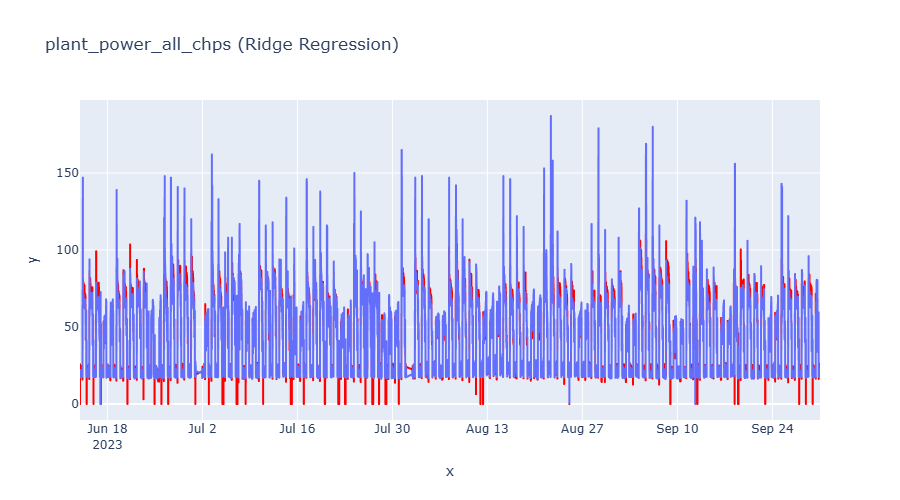

In [12]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Assuming chiller_data is already loaded

chps_feature = ['plant_cooling_rate'] + \
                [f'chiller_{i}_evap_water_flow_rate' for i in range(1, 6)]

chps_target = ['plant_power_all_chps']

X = chiller_data[chps_feature]
y = chiller_data[chps_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the Ridge model
ridge_model = Ridge(alpha=1)  # You can adjust the regularization parameter alpha as needed
ridge_model.fit(X_train, y_train)

# Predict
y_pred_ridge = ridge_model.predict(X_test)
y_pred_ridge = y_pred_ridge.clip(min=0)

# Performance Metrics for Ridge Regression
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

cvrmse_ridge = cvrmse(y_test, y_pred_ridge)

# Print metrics for Ridge Regression
print(f"Ridge Regression MSE: {mse_ridge}")
print(f"Ridge Regression MAE: {mae_ridge}")
print(f"Ridge Regression R²: {r2_ridge}")
print(f"Ridge Regression CvRMSE: {cvrmse_ridge}")

# Plotting
y_pred_ridge_df = pd.DataFrame(y_pred_ridge, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_ridge_df[chps_target[0]], title=f'{chps_target[0]} (Ridge Regression)')
fig.update_traces(line_color='red', name=f'{chps_target[0]} (Ridge)')
fig.add_trace(px.line(x=X_test.index, y=y_test[chps_target[0]]).data[0])
fig.show()

# Linear models for DQN

## Pumps

Linear Regression MSE: 252.0416522815366
Linear Regression MAE: 9.308368725739697
Linear Regression R²: 0.9258387984174042
Linear Regression CvRMSE: 0.18791014516983653


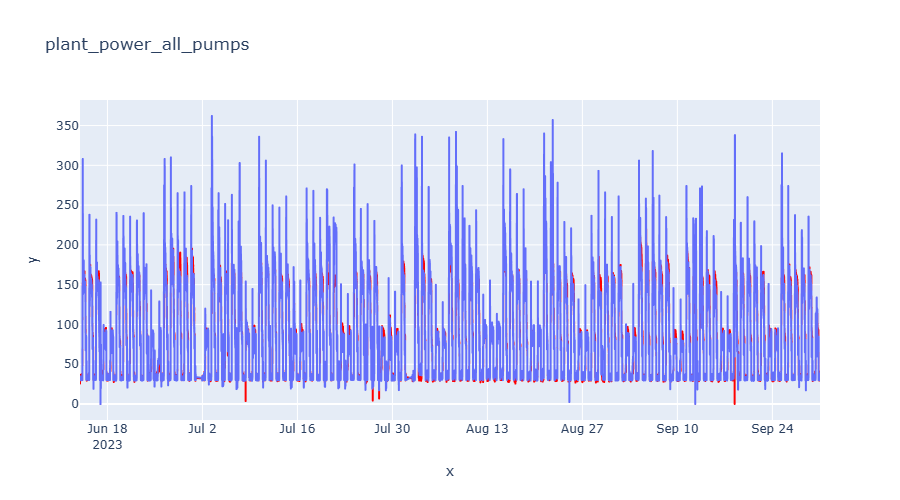

In [13]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

pumps_feature = ['plant_cooling_rate',
                'chilled_water_loop_flow_rate',
                'condenser_water_loop_flow_rate']

pumps_target = ['plant_power_all_pumps']

X = chiller_data[pumps_feature]
y = chiller_data[pumps_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Save the model
joblib.dump(lr_model, 'pumps_power_model.pkl')

# Predict
y_pred_lr = lr_model.predict(X_test)
y_pred_lr = y_pred_lr.clip(min=0)

# Performance Metrics
mse_lr = mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

cvrmse_lr = cvrmse(y_test, y_pred_lr)

# Print metrics
print(f"Linear Regression MSE: {mse_lr}")
print(f"Linear Regression MAE: {mae_lr}")
print(f"Linear Regression R²: {r2_lr}")
print(f"Linear Regression CvRMSE: {cvrmse_lr}")

# Plotting
y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_lr_df[pumps_target[0]], title=f'{pumps_target[0]}')
fig.update_traces(line_color='red', name=f'{pumps_target[0]}')
fig.add_trace(px.line(x=X_test.index, y=y_test[pumps_target[0]]).data[0])
fig.show()

## CTs

Linear Regression MSE: 20.491371191440866
Linear Regression MAE: 3.3922438079654724
Linear Regression R²: 0.9379787461237624
Linear Regression CvRMSE: 0.1884839541964359


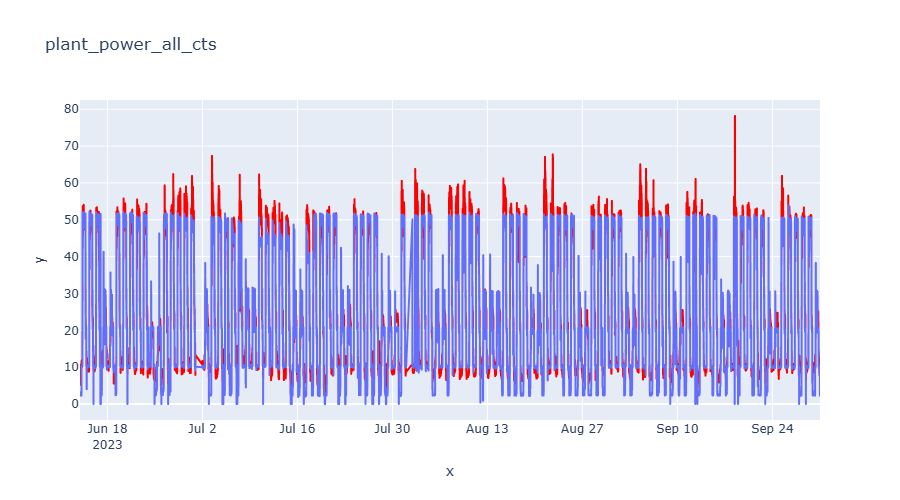

In [14]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

cts_feature = ['plant_cooling_rate',
            'outdoor_weather_station_wetbulb_temperature',
            'outdoor_weather_station_relative_humidity',
            # 'chilled_water_loop_return_water_temperature',
            # 'chilled_water_loop_supply_water_temperature',
            'chilled_water_loop_flow_rate',
            'condenser_water_loop_flow_rate']

cts_target = ['plant_power_all_cts']

X = chiller_data[cts_feature]
y = chiller_data[cts_target]

train_size = int(0.6 * len(X))
X_train, y_train = X[:train_size], y[:train_size]
X_test, y_test = X[train_size:], y[train_size:]

# Train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Save the model
joblib.dump(lr_model, 'cts_power_model.pkl')

# Predict
y_pred_lr = lr_model.predict(X_test)
y_pred_lr = y_pred_lr.clip(min=0)

# Performance Metrics
mse_lr = mean_squared_error(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

def cvrmse(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return rmse / np.mean(y_true)

cvrmse_lr = cvrmse(y_test, y_pred_lr)

# Print metrics
print(f"Linear Regression MSE: {mse_lr}")
print(f"Linear Regression MAE: {mae_lr}")
print(f"Linear Regression R²: {r2_lr}")
print(f"Linear Regression CvRMSE: {cvrmse_lr}")

# Plotting
y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_lr_df[cts_target[0]], title=f'{cts_target[0]}')
fig.update_traces(line_color='red', name=f'{cts_target[0]}')
fig.add_trace(px.line(x=X_test.index, y=y_test[cts_target[0]]).data[0])
fig.show()

## Chillers (return temp and power)

### return temp

Linear Regression MSE: 3.128359940296195
Linear Regression MAE: 1.33508783145483
Linear Regression R²: 0.537946452427988
Linear Regression CvRMSE: 0.03179220590988768


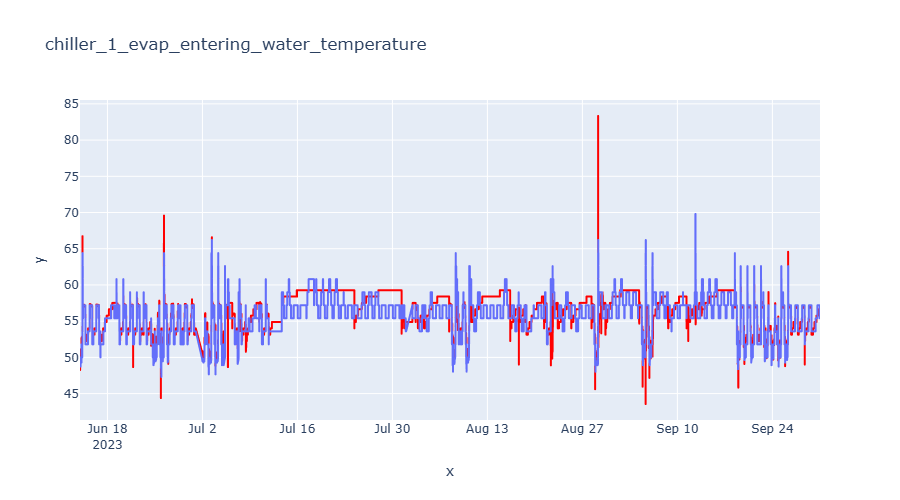

Linear Regression MSE: 1.557797509074893
Linear Regression MAE: 0.9330795319621541
Linear Regression R²: 0.8352078577637256
Linear Regression CvRMSE: 0.022977730955507567


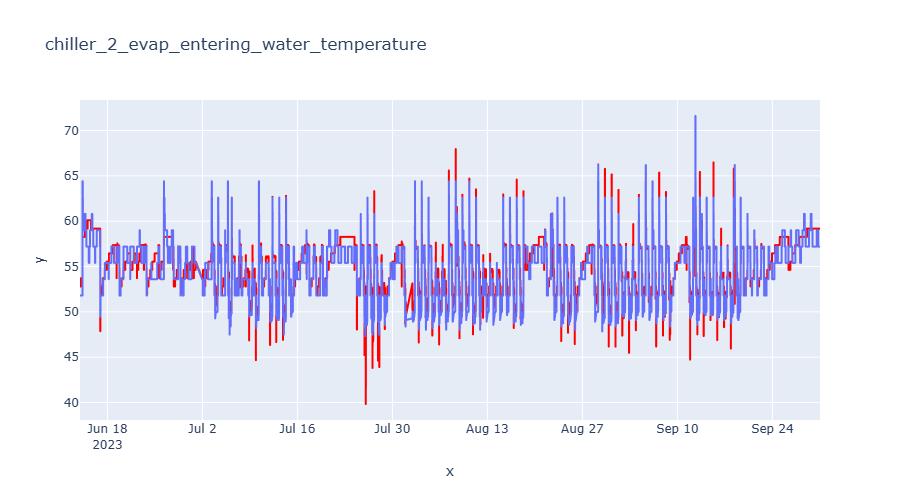

Linear Regression MSE: 1.7767876273752292
Linear Regression MAE: 0.8314358634222365
Linear Regression R²: 0.8104507322985262
Linear Regression CvRMSE: 0.024840937096718516


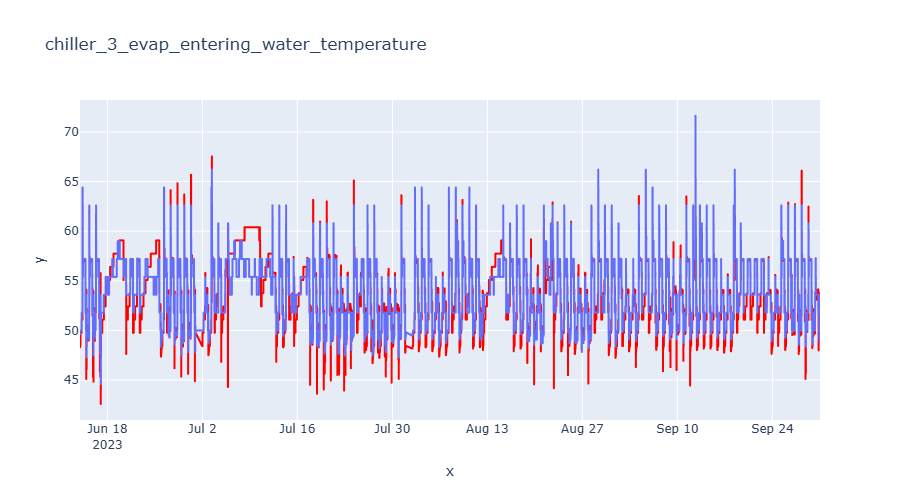

Linear Regression MSE: 1.663401869372232
Linear Regression MAE: 0.9780741074752776
Linear Regression R²: 0.7997620831186087
Linear Regression CvRMSE: 0.024047919843280856


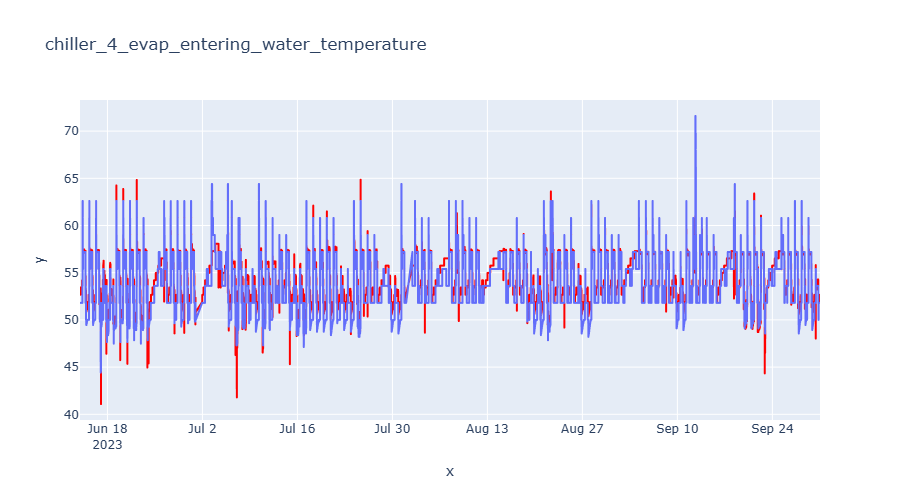

Linear Regression MSE: 1.856868003718283
Linear Regression MAE: 1.0391597091344869
Linear Regression R²: 0.7177595950954232
Linear Regression CvRMSE: 0.025170897489919537


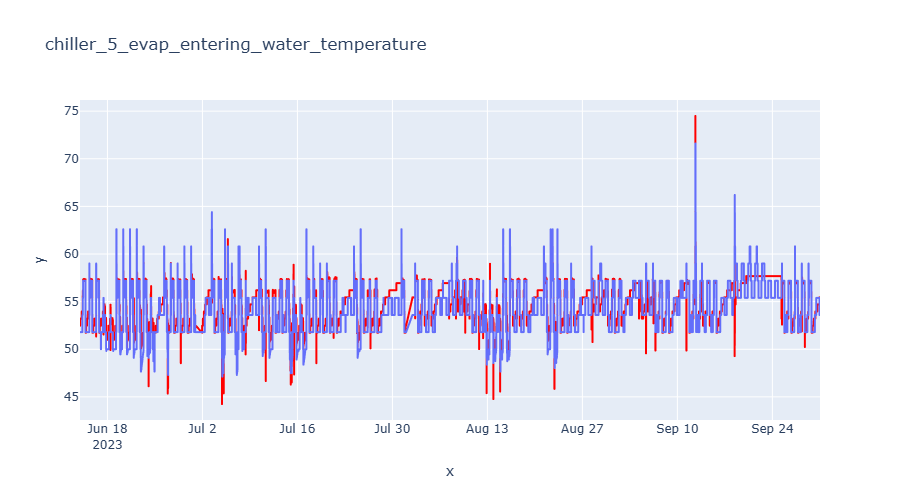

In [15]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

for chiller_id in range (1,6):
    chillers_feature = [f'chiller_{chiller_id}_cooling_rate',
            f'chiller_{chiller_id}_evap_leaving_water_temperature',
            f'chiller_{chiller_id}_evap_water_flow_rate',
            f'chiller_{chiller_id}_cond_water_flow_rate',
            f'chiller_{chiller_id}_status_read']

    chillers_target = [f'chiller_{chiller_id}_evap_entering_water_temperature']

    X = chiller_data[chillers_feature]
    y = chiller_data[chillers_target]

    train_size = int(0.6 * len(X))
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Train the model
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)

    # Save the model
    joblib.dump(lr_model, f'chiller_{chiller_id}_chwrt_lr_model.pkl')

    # Predict
    y_pred_lr = lr_model.predict(X_test)
    y_pred_lr = y_pred_lr.clip(min=0)

    # Performance Metrics
    mse_lr = mean_squared_error(y_test, y_pred_lr)
    mae_lr = mean_absolute_error(y_test, y_pred_lr)
    r2_lr = r2_score(y_test, y_pred_lr)

    def cvrmse(y_true, y_pred):
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        return rmse / np.mean(y_true)

    cvrmse_lr = cvrmse(y_test, y_pred_lr)

    # Print metrics
    print(f"Linear Regression MSE: {mse_lr}")
    print(f"Linear Regression MAE: {mae_lr}")
    print(f"Linear Regression R²: {r2_lr}")
    print(f"Linear Regression CvRMSE: {cvrmse_lr}")

    # Plotting
    y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_lr_df[chillers_target[0]], title=f'{chillers_target[0]}')
    fig.update_traces(line_color='red', name=f'{chillers_target[0]}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[chillers_target[0]]).data[0])
    fig.show()

### Power

Linear Regression MSE: 324.4970061755647
Linear Regression MAE: 6.644728898127901
Linear Regression R²: 0.9744860828097345
Linear Regression CvRMSE: 0.2894704292002026


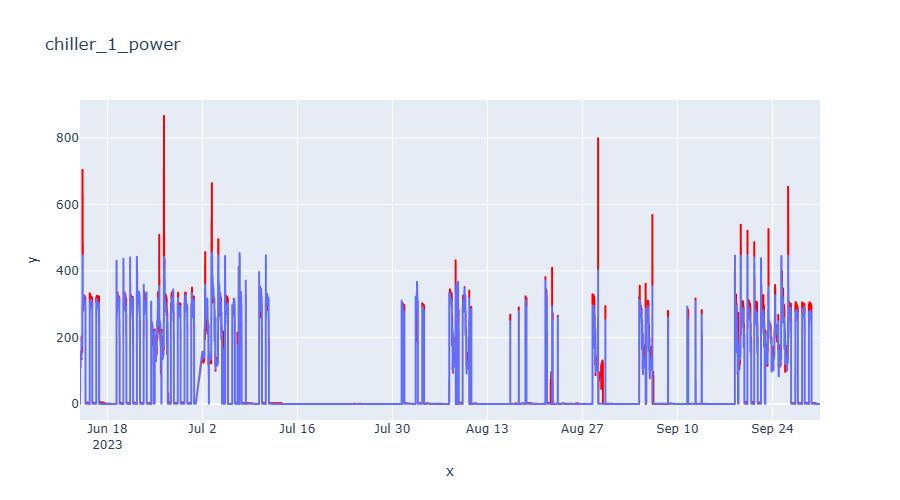

Linear Regression MSE: 467.28699117185636
Linear Regression MAE: 11.498689246404826
Linear Regression R²: 0.976742827157111
Linear Regression CvRMSE: 0.17385443406331547


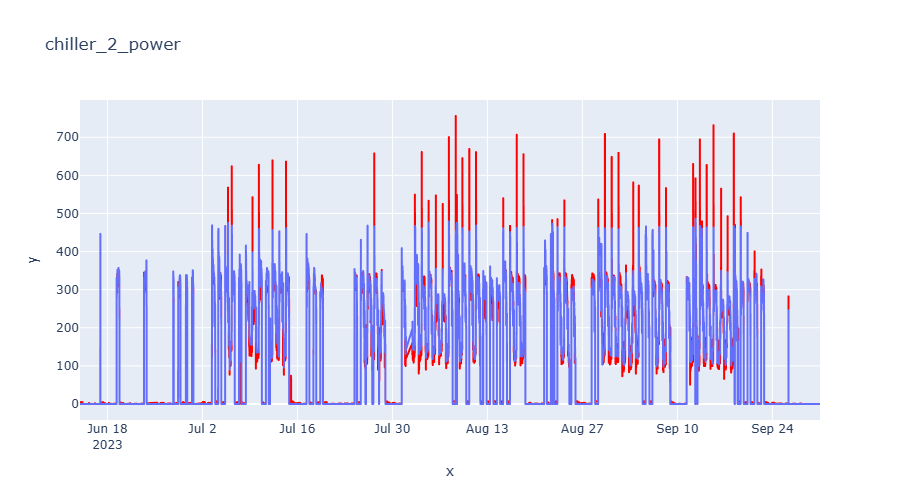

Linear Regression MSE: 4140.2062670002815
Linear Regression MAE: 23.94078257027445
Linear Regression R²: 0.7775184608029071
Linear Regression CvRMSE: 0.42739778859693744


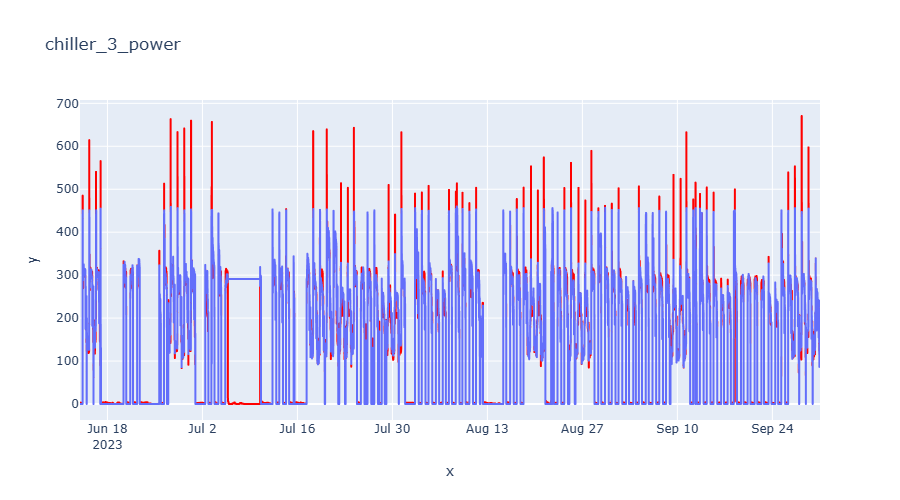

Linear Regression MSE: 373.1170605604579
Linear Regression MAE: 10.3536152662436
Linear Regression R²: 0.9803067308365717
Linear Regression CvRMSE: 0.15636521937581097


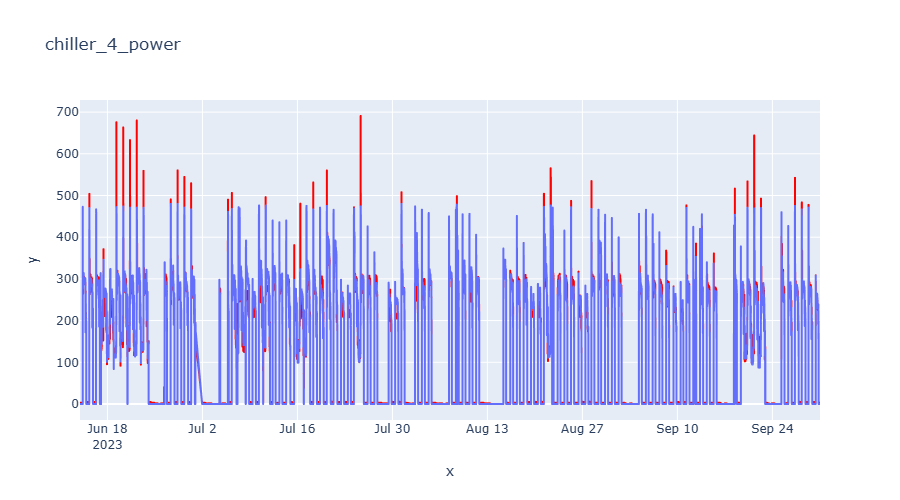

Linear Regression MSE: 232.8862065666822
Linear Regression MAE: 6.386001212045432
Linear Regression R²: 0.9848243404595135
Linear Regression CvRMSE: 0.17464049294466386


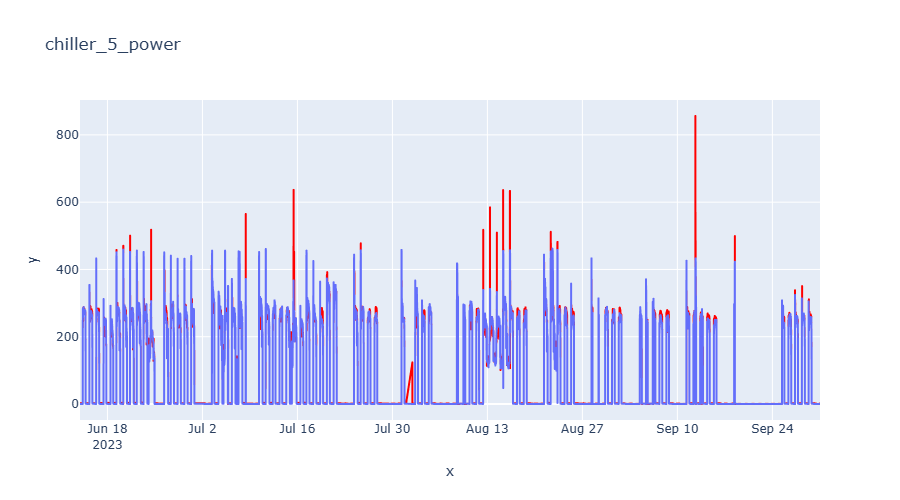

: 

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib

for chiller_id in range (1,6):
    chillers_feature = [f'chiller_{chiller_id}_cooling_rate',
            f'chiller_{chiller_id}_evap_leaving_water_temperature',
            f'chiller_{chiller_id}_evap_entering_water_temperature',
            f'chiller_{chiller_id}_evap_water_flow_rate',
            f'chiller_{chiller_id}_cond_water_flow_rate',
            f'chiller_{chiller_id}_status_read']

    chillers_target = [f'chiller_{chiller_id}_power']

    X = chiller_data[chillers_feature]
    y = chiller_data[chillers_target]

    train_size = int(0.6 * len(X))
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Train the model
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)

    # Save the model
    joblib.dump(lr_model, f'chiller_{chiller_id}_power_lr_model.pkl')

    # Predict
    y_pred_lr = lr_model.predict(X_test)
    y_pred_lr = y_pred_lr.clip(min=0)

    # Performance Metrics
    mse_lr = mean_squared_error(y_test, y_pred_lr)
    mae_lr = mean_absolute_error(y_test, y_pred_lr)
    r2_lr = r2_score(y_test, y_pred_lr)

    def cvrmse(y_true, y_pred):
        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        return rmse / np.mean(y_true)

    cvrmse_lr = cvrmse(y_test, y_pred_lr)

    # Print metrics
    print(f"Linear Regression MSE: {mse_lr}")
    print(f"Linear Regression MAE: {mae_lr}")
    print(f"Linear Regression R²: {r2_lr}")
    print(f"Linear Regression CvRMSE: {cvrmse_lr}")

    # Plotting
    y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_lr_df[chillers_target[0]], title=f'{chillers_target[0]}')
    fig.update_traces(line_color='red', name=f'{chillers_target[0]}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[chillers_target[0]]).data[0])
    fig.show()